c:\Users\idden\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\idden\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
c:\Users\idden\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\ma\core.py:2896: ComplexWarning: Casting complex values to real discards the imaginary part
  _data = np.array(data, dtype=dtype, copy=copy,


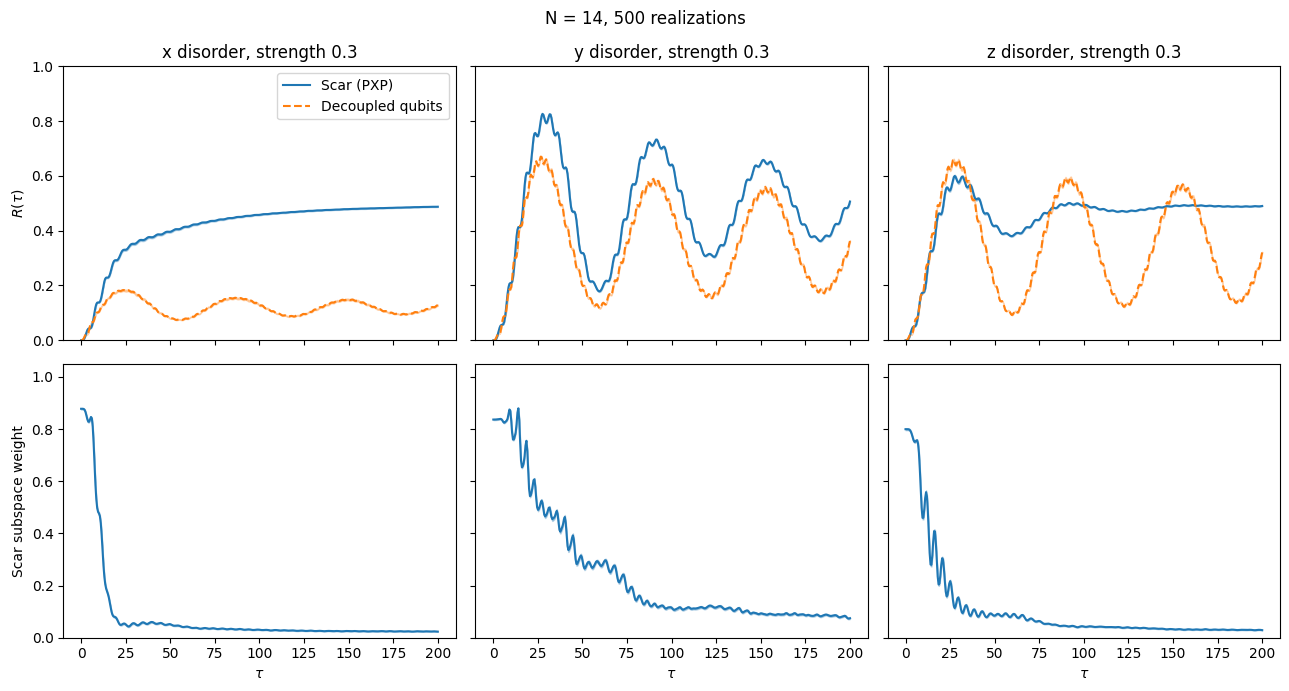

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

N = 14
dis = 0.3
data_dir = "xyz_data"

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey="row")

for col, dis_type in enumerate(["x", "y", "z"]):
    d = np.load(os.path.join(data_dir, f"{dis_type}_dis_N{N}_error_bands.npz"))
    t = d["tlist"]
    reals = d["scar"].shape[0]

    # bands are mean +/- standard error of the mean over realizations
    # (delete "/ np.sqrt(reals)" to shade the realization-to-realization spread instead)

    # row 1: R(tau), scar solid, decoupled qubits dashed
    for arr, style, color, label in [(d["scar"], "-", "C0", "Scar (PXP)"),
                                     (d["qubit"], "--", "C1", "Decoupled qubits")]:
        mean = arr.mean(axis=0)
        err = arr.std(axis=0) / np.sqrt(reals)
        axes[0, col].plot(t, mean, style, color=color, label=label)
        axes[0, col].fill_between(t, mean - err, mean + err, color=color, alpha=0.3)

    # row 2: scar subspace weight (scar model only)
    mean = d["scarProbs"].mean(axis=0)
    err = d["scarProbs"].std(axis=0) / np.sqrt(reals)
    axes[1, col].plot(t, mean, color="C0")
    axes[1, col].fill_between(t, mean - err, mean + err, color="C0", alpha=0.3)

    axes[0, col].set_title(f"{dis_type} disorder, strength {dis}")
    axes[1, col].set_xlabel(r"$\tau$")

axes[0, 0].set_ylabel(r"$R(\tau)$")
axes[1, 0].set_ylabel("Scar subspace weight")
axes[0, 0].set_ylim(0, 1)
axes[1, 0].set_ylim(0, 1.05)
axes[0, 0].legend()

fig.suptitle(f"N = {N}, {reals} realizations")
fig.tight_layout()
fig.savefig(f"xyz_N{N}_Rtau_scarweight.pdf")
plt.show()